# Tune metadata models with separate patient checks: deduplicated Subset data

Does choosing model settings within training data improve predictions for held-out patients? We return to the spline and tree models in [05_metadata_models.ipynb](05_metadata_models.ipynb), using age, sex and anatomical site, the metadata alongside each image.

The saved search raises spline average precision (AP) from 0.0492 to 0.0502 pooled (0.0648 to 0.0688 mean-fold) but lowers ROC-AUC from 0.6428 to 0.6332 pooled. Both tree searches lower AP. Keep the fixed spline as the primary method and the tuned spline as a sensitivity check. The reserved test is not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [07_metadata_tuning.ipynb](../Subset/07_metadata_tuning.ipynb).

The clean workflow's primary ranking measure is **unweighted mean outer-fold AP**. The original pooled tables and figures are retained for presentation consistency and are explicitly secondary; their values are not interchangeable with mean-fold scores.

## Context and methods

Tuning searches settings that control a model's flexibility. Selecting them on the same patients used to report performance could favour lucky choices. Nested cross-validation separates these roles with two levels of patient groups, or folds.

For each of five outer folds, reserve its patients for assessment. Use three inner patient folds within the other patients. **Membership qualification:** no original execution membership receipt was saved, so the separate clean runner reconstructed the original seed-42-plus-outer split using the original 6,864-row CSV order, froze those patient assignments and then filtered retained images. This is a documented reconstruction, not a recovered execution receipt; no splitter is rerun on the 6,706 retained rows. Compare settings on those inner groups, choose the highest mean AP and fit on all outer-training patients. Predict the outer group once. This evaluates the selection procedure, whose chosen settings can differ between folds.

The spline tries 18 combinations of regularisation, knots and degree. Regularisation restrains fitting; knots and degree control the age curve's shape. Each tree method tries 12 combinations. Every search includes the original settings, and all preprocessing is fitted within training.

Average precision (AP) is primary because it rewards ranking rare malignant images near the top. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance. Higher is better for both. Log loss and Brier score measure probability error; lower is better.

The outer folds have guided earlier model choices. Nested selection prevents direct use of their labels in their own search, but these remain development results rather than independent final-test evidence.


## Data

### 1. Set paths and imports

Use the shared Subset fold file and project Python kernel. Output paths identify the saved tables and figures. Re-executing the modelling cells repeats the searches and replaces their named outputs.


In [1]:
NOTEBOOK_STAGE = '07_metadata_tuning'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss,
    roc_auc_score, roc_curve, precision_recall_curve,
)
from melanoma_detection.metadata_evaluation import probability_metrics, decision_metrics, calibration_bins
from melanoma_detection.dedup_notebook_metadata import (
    saved_metadata, metric_table, exploratory_cutoff, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
from melanoma_detection.dedup_notebook_metadata_templates import marginal_age_profile, metadata_patient_intervals
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
PROJECT_ROOT = ROOT
train = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
assert np.array_equal(train.patient_id, frame.patient_id)
assert np.array_equal(train.target, frame.target)
assert np.array_equal(train.fold, frame.fold)
assert train.groupby("patient_id").fold.nunique().eq(1).all()
assert train.image_name.is_unique and len(train) == 6706
assert int(train.target.sum()) == 127
FEATURE_COLUMNS = ["sex", "age_approx", "anatom_site_general_challenge"]
FEATURES = FEATURE_COLUMNS
DATA_PATH = ROOT / "data/subset/processed/dedup_v1/dataset_manifest.json"
TRAIN_FOLDS_PATH = DATA_PATH
REPORT_DIR = ROOT / "results/dedup_v1/clean_workflow/metadata_depth" / NOTEBOOK_STAGE
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = FIGURE_DIR
TABLES = METRICS = PREDICTIONS = REPORT_DIR
plt.rcdefaults()

from melanoma_detection.dedup_metadata_suite import GRIDS
from sklearn.model_selection import ParameterGrid
selected = pd.read_csv(meta["suite"] / "selected_parameters.csv")
candidates = pd.read_csv(meta["suite"] / "inner_candidates.csv")
PARAMETERS_PATH = REPORT_DIR / "metadata_tuning_best_parameters_dedup_v1.csv"
METRICS_PATH = REPORT_DIR / "metadata_tuning_metrics_dedup_v1.csv"
ROC_AUC_BARS_PATH = FIGURE_DIR / "metadata_tuning_roc_auc_dedup_v1.png"
AVERAGE_PRECISION_BARS_PATH = FIGURE_DIR / "metadata_tuning_ap_dedup_v1.png"
CURVES_PATH = FIGURE_DIR / "metadata_tuning_curves_dedup_v1.png"

ORIGINAL_EXPORT_DPI = 320


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

### 2. Load and check the retained development data

Confirm that the required fields and five folds are present and every patient's images stay in one outer fold. The counts below should match the earlier metadata notebooks, allowing us to compare the methods on the same data.


In [2]:

print(f"Manifest: {DATA_PATH.relative_to(ROOT)}")
print(f"Dataset identity: {bundle['identity']['dataset_identity']}")
print(f"Images: {len(train):,}; patients: {train.patient_id.nunique():,}")
print(f"Malignant images: {int(train.target.sum()):,} ({train.target.mean():.2%})")
print(f"Malignant patients: {train.loc[train.target.eq(1), 'patient_id'].nunique():,}")
print("Original patient folds retained; reserved test not loaded.")


Manifest: data\subset\processed\dedup_v1\dataset_manifest.json
Dataset identity: 0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae9f9eb7e57825b04af1
Images: 6,706; patients: 422
Malignant images: 127 (1.89%)
Malignant patients: 88
Original patient folds retained; reserved test not loaded.


### 3. Inspect the saved model pipelines and search grids

Each pipeline includes both preprocessing and the model. A fresh training fit learns its own age transformation and category columns. This prevents validation patients from influencing the features used during their model's fitting.


In [3]:

grid_rows = [{"model": model, "parameter": parameter.rsplit("__", 1)[-1],
    "values": str(values), "candidates": len(list(ParameterGrid(grid)))}
    for model, grid in GRIDS.items() for parameter, values in grid.items()]
display(pd.DataFrame(grid_rows))
display(pd.DataFrame([meta["core"]["specification"]["spline"]]).T)


,model,parameter,values,candidates
0,spline,C,"[0.1, 1.0, 10.0]",18
1,spline,n_knots,"[3, 4, 5]",18
2,spline,degree,"[2, 3]",18
3,random_forest,max_depth,"[4, 8, None]",12
4,random_forest,min_samples_leaf,"[5, 15]",12
5,random_forest,max_features,"['sqrt', 1.0]",12
6,xgboost,max_depth,"[2, 3]",12
7,xgboost,learning_rate,"[0.03, 0.05, 0.1]",12
8,xgboost,min_child_weight,"[1, 5]",12


,0
model,fixed_spline_logistic
features,"[age_approx, sex, anatom_site_general_challenge]"
age_knots,4
age_degree,3
age_knot_placement,quantile
logistic_C,1.0
class_weight,None
seed,42
primary_probability,raw
threshold_rule,highest cutoff attaining training OOF recall


## Results

### 4. Load the fixed models and completed setting searches

For each outer fold, the completed versions trained on the same patients and predicted the same held-out patients. The tuned version also used inner patient folds to select settings. This keeps the comparison focused on the selection procedure.


In [4]:

model_setups = {"Spline logistic": ("spline_raw", "spline_tuned"),
    "Random forest": ("random_forest", "random_forest_tuned"), "XGBoost": ("xgboost", "xgboost_tuned")}
untuned_oof = {name: scores[keys[0]] for name, keys in model_setups.items()}
tuned_oof = {name: scores[keys[1]] for name, keys in model_setups.items()}
family_labels = {"spline": "Spline logistic", "random_forest": "Random forest", "xgboost": "XGBoost"}
parameter_records = []
for row in selected.itertuples():
    text = ", ".join(f"{key.rsplit('__', 1)[-1]}={value}" for key, value in json.loads(row.best_parameters).items())
    parameter_records.append({"Outer fold": row.outer_fold, "Model": family_labels[row.model],
        "Inner best average precision": row.inner_best_average_precision, "Best parameters": text})
assert len(parameter_records) == 15 and len(candidates) == 210
print("Loaded completed patient-nested searches: 630 inner fits and 15 tuned outer refits.")


Loaded completed patient-nested searches: 630 inner fits and 15 tuned outer refits.


### 5. Check how often the same settings are selected

The first table records the choice within each outer-training group. The second counts how often the same combination wins. Similar choices across folds would suggest that the preferred settings are less sensitive to the training sample. Different choices can still work, but they give less support for adopting one fixed tuned combination.

The inner best AP is the score used to make a choice. It can favour a lucky setting and should not be read as the final performance estimate; use the outer scores below for that.


In [5]:
best_parameters = pd.DataFrame(parameter_records)
parameter_frequency = (
    best_parameters.value_counts(["Model", "Best parameters"])
    .rename("Outer folds selected")
    .reset_index()
)

PARAMETERS_PATH.parent.mkdir(parents=True, exist_ok=True)
best_parameters.to_csv(PARAMETERS_PATH, index=False)
with pd.option_context("display.max_colwidth", None):
    display(best_parameters.round({"Inner best average precision": 4}))
    display(parameter_frequency)

,Outer fold,Model,Inner best average precision,Best parameters
0,0,Spline logistic,0.0535,"C=0.1, degree=2, n_knots=5"
1,0,Random forest,0.0469,"max_depth=4, max_features=sqrt, min_samples_leaf=15"
2,0,XGBoost,0.0458,"learning_rate=0.05, max_depth=3, min_child_weight=1"
3,1,Spline logistic,0.0650,"C=0.1, degree=2, n_knots=5"
4,1,Random forest,0.0629,"max_depth=None, max_features=sqrt, min_samples_leaf=15"
5,1,XGBoost,0.0547,"learning_rate=0.03, max_depth=3, min_child_weight=1"
6,2,Spline logistic,0.0773,"C=1.0, degree=2, n_knots=4"
7,2,Random forest,0.0728,"max_depth=4, max_features=1.0, min_samples_leaf=5"
8,2,XGBoost,0.0760,"learning_rate=0.1, max_depth=2, min_child_weight=1"
9,3,Spline logistic,0.0605,"C=0.1, degree=3, n_knots=3"


,Model,Best parameters,Outer folds selected
0,Spline logistic,"C=0.1, degree=2, n_knots=5",3
1,Random forest,"max_depth=4, max_features=sqrt, min_samples_leaf=15",3
2,XGBoost,"learning_rate=0.05, max_depth=3, min_child_weight=1",1
3,Random forest,"max_depth=None, max_features=sqrt, min_samples_leaf=15",1
4,XGBoost,"learning_rate=0.03, max_depth=3, min_child_weight=1",1
5,Spline logistic,"C=1.0, degree=2, n_knots=4",1
6,Random forest,"max_depth=4, max_features=1.0, min_samples_leaf=5",1
7,XGBoost,"learning_rate=0.1, max_depth=2, min_child_weight=1",1
8,Spline logistic,"C=0.1, degree=3, n_knots=3",1
9,XGBoost,"learning_rate=0.03, max_depth=2, min_child_weight=5",1


### 6. Compare the held-out results

The original first table pools predictions across all outer folds. The second shows AP changes within each fold. A positive "Tuned minus untuned" value favours tuning; a negative value favours the fixed model. The additional mean-fold table is the primary clean ranking view. Read the pooled score and fold changes together so one favourable group does not hide inconsistent results.


In [6]:
def probability_metrics(targets, probabilities):
    return {
        "ROC-AUC": roc_auc_score(targets, probabilities),
        "Average precision": average_precision_score(targets, probabilities),
        "Log loss": log_loss(targets, probabilities, labels=[0, 1]),
        "Brier score": brier_score_loss(targets, probabilities),
    }


model_probabilities = {}
for model_name in model_setups:
    model_probabilities[(model_name, "Untuned")] = untuned_oof[model_name]
    model_probabilities[(model_name, "Nested-tuned")] = tuned_oof[model_name]

metric_comparison = pd.DataFrame(
    [
        {
            "Model": model_name,
            "Version": version,
            **probability_metrics(train["target"], probabilities),
        }
        for (model_name, version), probabilities in model_probabilities.items()
    ]
).set_index(["Model", "Version"])

fold_records = []
for fold in sorted(train["fold"].unique()):
    fold_rows = train["fold"].eq(fold)
    for (model_name, version), probabilities in model_probabilities.items():
        fold_records.append(
            {
                "Outer fold": int(fold),
                "Model": model_name,
                "Version": version,
                **probability_metrics(train.loc[fold_rows, "target"], probabilities[fold_rows]),
            }
        )

fold_metrics = pd.DataFrame(fold_records)
fold_ap = fold_metrics.pivot(
    index=["Model", "Outer fold"], columns="Version", values="Average precision"
)
fold_ap["Tuned minus untuned"] = fold_ap["Nested-tuned"] - fold_ap["Untuned"]
METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)
metric_comparison.reset_index().to_csv(METRICS_PATH, index=False)
display(metric_comparison.round(4))
display(fold_ap.round(4))
primary_rows = []
for model_name, keys in model_setups.items():
    for version, key in zip(["Untuned", "Nested-tuned"], keys):
        row = metric_table(frame, scores, [key]).query("scope == 'mean_fold'").iloc[0]
        primary_rows.append({"Model": model_name, "Version": version, "Mean-fold AP": row.average_precision,
            "Mean-fold ROC-AUC": row.roc_auc, "Mean-fold log loss": row.log_loss, "Mean-fold Brier": row.brier})
display(pd.DataFrame(primary_rows).set_index(["Model", "Version"]).round(5))


ROC-AUC  Average precision  Log loss  \
Model           Version                                              
Spline logistic Untuned        0.6428             0.0492    0.0909   
                Nested-tuned   0.6332             0.0502    0.0911   
Random forest   Untuned        0.6033             0.0433    0.0919   
                Nested-tuned   0.6141             0.0406    0.0922   
XGBoost         Untuned        0.5893             0.0434    0.0938   
                Nested-tuned   0.5681             0.0379    0.0944   

                              Brier score  
Model           Version                    
Spline logistic Untuned            0.0184  
                Nested-tuned       0.0184  
Random forest   Untuned            0.0184  
                Nested-tuned       0.0185  
XGBoost         Untuned            0.0185  
                Nested-tuned       0.0186

Version                     Nested-tuned  Untuned  Tuned minus untuned
Model           Outer fold                                            
Random forest   0                 0.0390   0.0415              -0.0025
                1                 0.0431   0.0559              -0.0127
                2                 0.0320   0.0324              -0.0004
                3                 0.0724   0.0609               0.0115
                4                 0.0737   0.0832              -0.0095
Spline logistic 0                 0.0687   0.0662               0.0025
                1                 0.0669   0.0460               0.0209
                2                 0.0357   0.0373              -0.0016
                3                 0.0590   0.0624              -0.0034
                4                 0.1137   0.1122               0.0015
XGBoost         0                 0.0522   0.0522               0.0000
                1                 0.0610   0.0623              -0.0013
                2                 0.0268   0.0264               0.0004
                3                 0.0369   0.0690              -0.0320
                4                 0.0860   0.0855               0.0005

Mean-fold AP  Mean-fold ROC-AUC  \
Model           Version                                         
Spline logistic Untuned            0.06484            0.65563   
                Nested-tuned       0.06881            0.64303   
Random forest   Untuned            0.05477            0.60319   
                Nested-tuned       0.05205            0.62673   
XGBoost         Untuned            0.05907            0.59304   
                Nested-tuned       0.05258            0.56732   

                              Mean-fold log loss  Mean-fold Brier  
Model           Version                                            
Spline logistic Untuned                  0.09101          0.01842  
                Nested-tuned             0.09115          0.01840  
Random forest   Untuned                  0.09195          0.01845  
                Nested-tuned             0.09222          0.01849  
XGBoost         Untuned                  0.09385          0.01851  
                Nested-tuned             0.09450          0.01857

### 7. Read the score comparison charts

The horizontal axis names model families. Blue bars use fixed settings; gold bars use settings selected within training. The first figure shows ROC-AUC vertically; the second shows AP. Higher bars are better, axes start at zero and annotations give exact scores.

Compare bars within each family, then compare the two measures. Spline AP rises while ROC-AUC falls; both tree models lose AP, while forest ROC-AUC rises and XGBoost ROC-AUC falls. These preserve the original separate AP and ROC-AUC figures and pooled aggregation. Read them alongside primary mean-fold scores. There are no uncertainty bars, so a small observed gain is not established as repeatable.


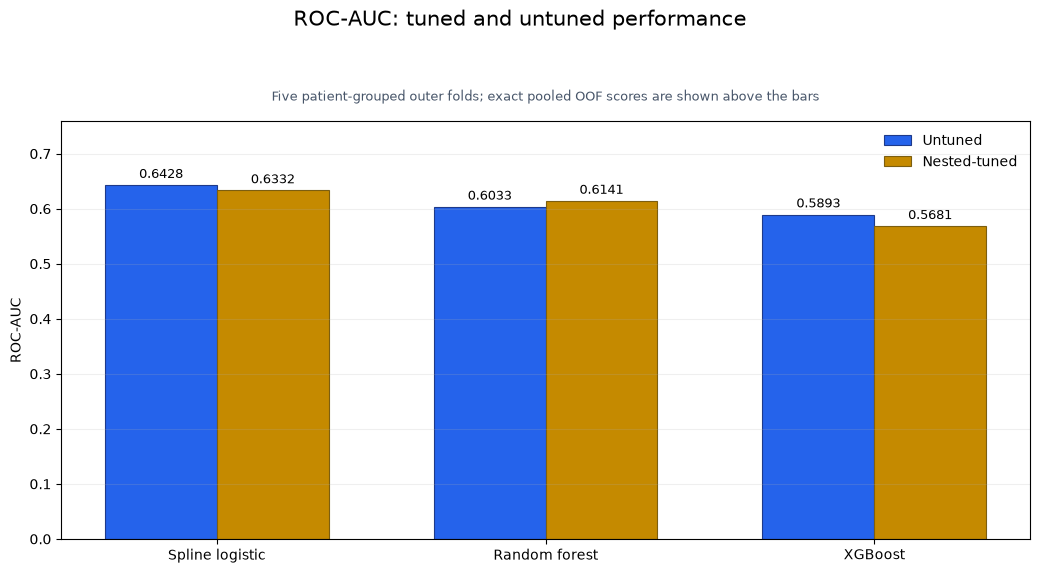

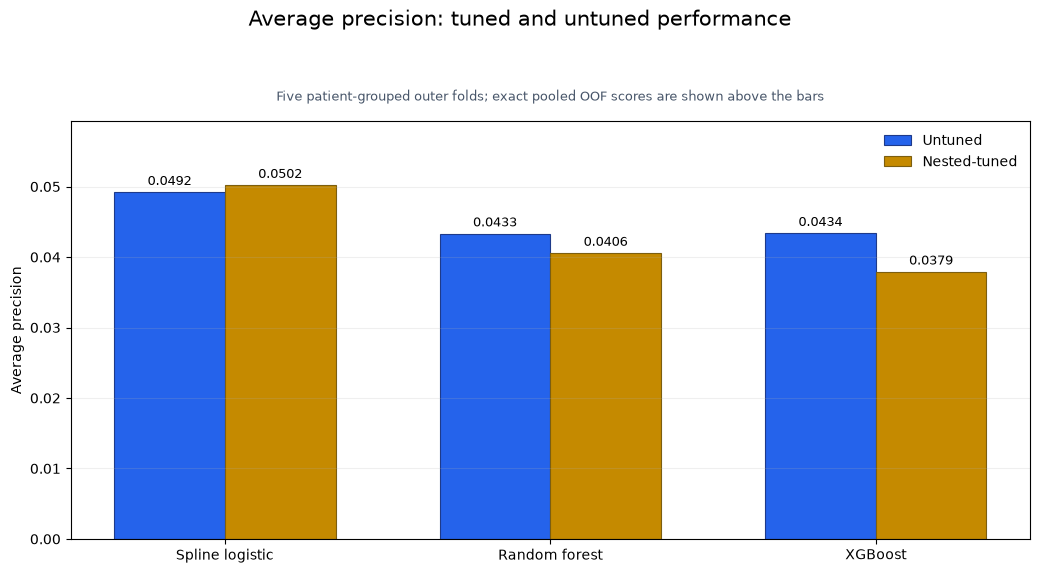

In [7]:
bar_models = list(model_setups)
bar_positions = np.arange(len(bar_models), dtype=float)
bar_width = 0.34
bar_colors = {"Untuned": "#2563EB", "Nested-tuned": "#C58A00"}
bar_edges = {"Untuned": "#1E3A8A", "Nested-tuned": "#7C5E10"}


def plot_tuning_bars(metric_name, save_path):
    untuned_values = np.array(
        [metric_comparison.loc[(model, "Untuned"), metric_name] for model in bar_models]
    )
    tuned_values = np.array(
        [metric_comparison.loc[(model, "Nested-tuned"), metric_name] for model in bar_models]
    )

    untuned_positions = bar_positions - bar_width / 2
    tuned_positions = bar_positions + bar_width / 2

    fig, axis = plt.subplots(figsize=(10.5, 5.8))
    untuned_bars = axis.bar(
        untuned_positions, untuned_values, bar_width, label="Untuned",
        color=bar_colors["Untuned"], edgecolor=bar_edges["Untuned"], linewidth=0.8,
    )
    tuned_bars = axis.bar(
        tuned_positions, tuned_values, bar_width, label="Nested-tuned",
        color=bar_colors["Nested-tuned"], edgecolor=bar_edges["Nested-tuned"], linewidth=0.8,
    )
    axis.bar_label(untuned_bars, fmt="%.4f", padding=3, fontsize=9)
    axis.bar_label(tuned_bars, fmt="%.4f", padding=3, fontsize=9)
    axis.set_ylabel(metric_name)
    axis.set_xticks(bar_positions, labels=bar_models)
    axis.set_ylim(0, max(untuned_values.max(), tuned_values.max()) * 1.18)
    axis.grid(axis="y", alpha=0.20)
    axis.legend(frameon=False, loc="upper right")
    fig.suptitle(f"{metric_name}: tuned and untuned performance", fontsize=15, y=0.98)
    axis.set_title(
        "Five patient-grouped outer folds; exact pooled OOF scores are shown above the bars",
        fontsize=9, color="#475569", pad=15,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=320, bbox_inches="tight")
    finish_figure(fig, save_path.stem)


plot_tuning_bars("ROC-AUC", ROC_AUC_BARS_PATH)
plot_tuning_bars("Average precision", AVERAGE_PRECISION_BARS_PATH)

### 8. Read the ROC and precision-recall curves

Each row shows one model family. Blue dashed lines use the fixed settings and gold solid lines use the settings selected within training data.

On the left, the horizontal axis is the fraction of benign images wrongly flagged and the vertical axis is the fraction of malignant images found (recall). A curve nearer the upper-left corner is preferable; the grey dotted diagonal marks chance-level ranking.

On the right, the horizontal axis is recall and the vertical axis is precision, the fraction of flagged images that are malignant. A higher curve at the same recall means fewer false alarms among flagged images. The grey dotted line marks the 1.89% malignant-image rate. Precision is shown only from 0-30% to make these low values easier to compare.

The curves show where tuning helps or hurts across cutoffs. Crossing curves mean a version can perform better in one recall range and worse in another, even when one pooled score is higher.


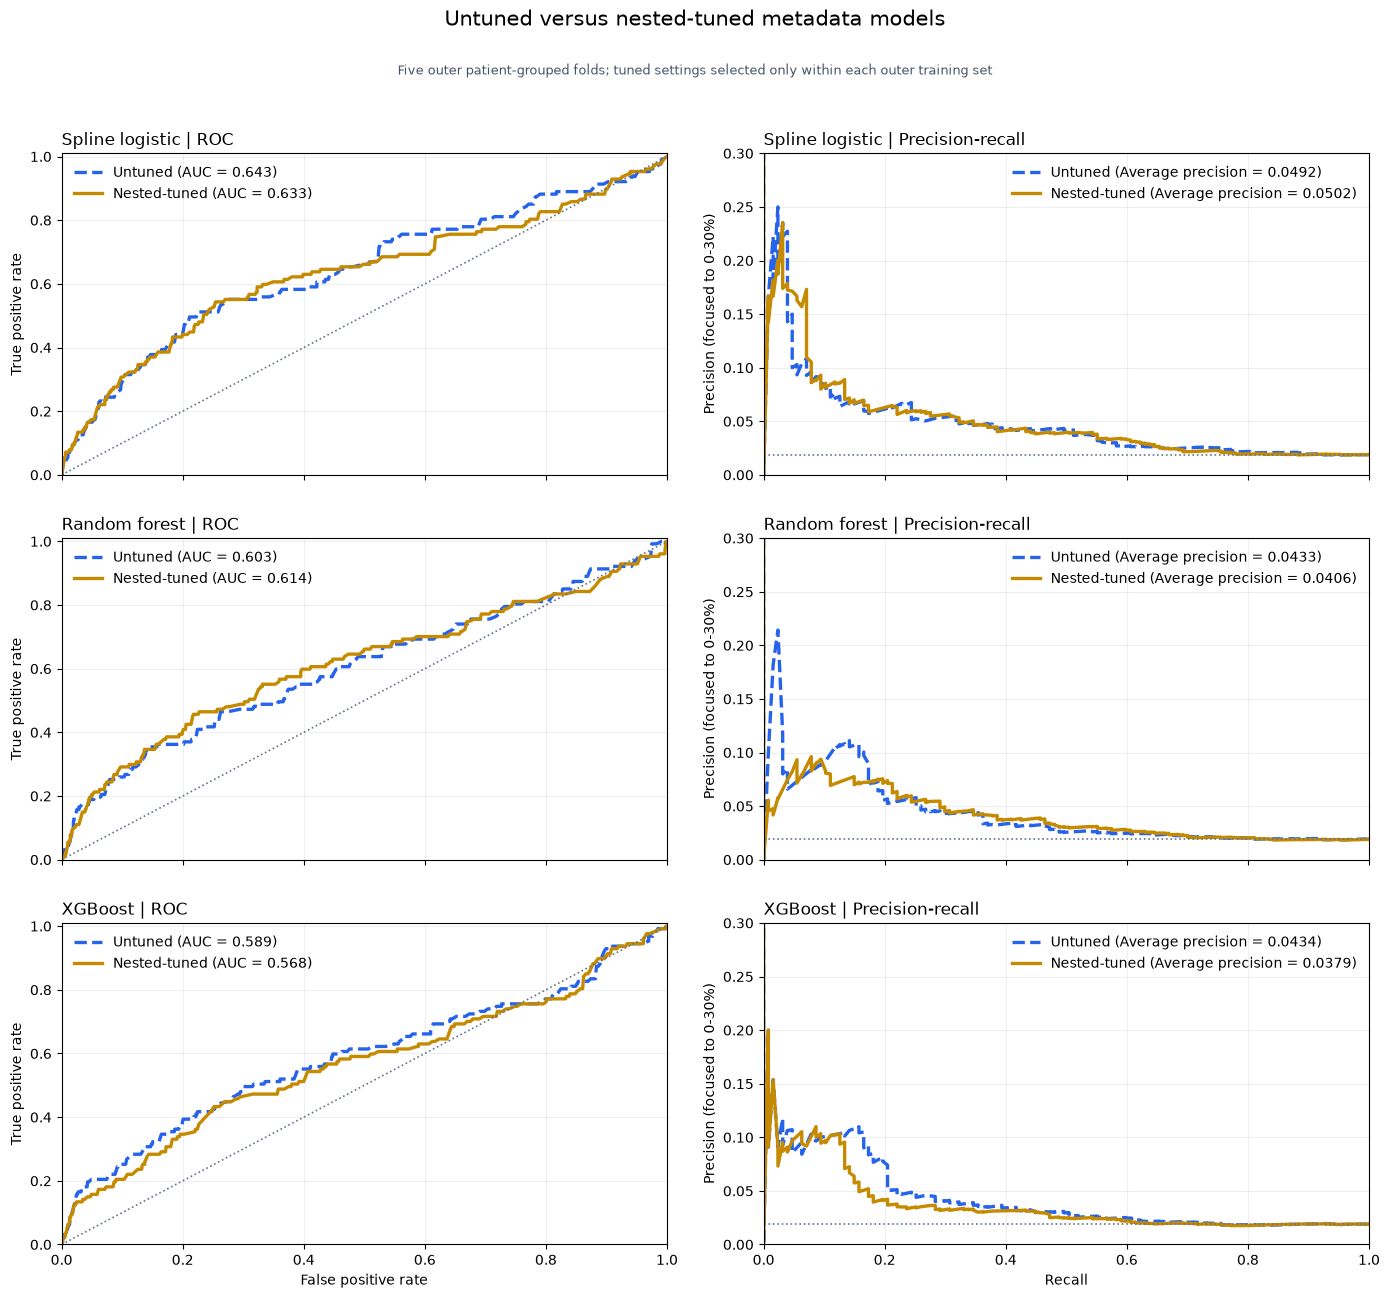

In [8]:
colors = {"Untuned": "#2563EB", "Nested-tuned": "#C58A00"}
line_styles = {"Untuned": "--", "Nested-tuned": "-"}
fig, axes = plt.subplots(len(model_setups), 2, figsize=(14, 13), sharex="col", sharey="col")

for row, model_name in enumerate(model_setups):
    roc_axis, pr_axis = axes[row]
    for version in ("Untuned", "Nested-tuned"):
        probabilities = model_probabilities[(model_name, version)]
        false_positive_rate, true_positive_rate, _ = roc_curve(train["target"], probabilities)
        precision, recall, _ = precision_recall_curve(train["target"], probabilities)
        scores = metric_comparison.loc[(model_name, version)]

        roc_axis.plot(
            false_positive_rate, true_positive_rate,
            color=colors[version], linestyle=line_styles[version], linewidth=2.4,
            label=f"{version} (AUC = {scores['ROC-AUC']:.3f})",
        )
        pr_axis.plot(
            recall, precision,
            color=colors[version], linestyle=line_styles[version], linewidth=2.4,
            label=f"{version} (Average precision = {scores['Average precision']:.4f})",
        )

    roc_axis.plot([0, 1], [0, 1], color="#64748B", linestyle=":", linewidth=1.2)
    pr_axis.axhline(train["target"].mean(), color="#64748B", linestyle=":", linewidth=1.2)
    roc_axis.set_title(f"{model_name} | ROC", loc="left")
    pr_axis.set_title(f"{model_name} | Precision-recall", loc="left")
    roc_axis.set_ylabel("True positive rate")
    pr_axis.set_ylabel("Precision (focused to 0-30%)")
    roc_axis.set_xlim(0, 1)
    roc_axis.set_ylim(0, 1.01)
    pr_axis.set_xlim(0, 1)
    pr_axis.set_ylim(0, 0.30)
    for axis in (roc_axis, pr_axis):
        axis.grid(alpha=0.20)
        axis.legend(frameon=False)

axes[-1, 0].set_xlabel("False positive rate")
axes[-1, 1].set_xlabel("Recall")
fig.suptitle("Untuned versus nested-tuned metadata models", fontsize=15, y=0.995)
fig.text(
    0.5, 0.945,
    "Five outer patient-grouped folds; tuned settings selected only within each outer training set",
    ha="center", color="#475569", fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.4, w_pad=1.8)
CURVES_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(CURVES_PATH, dpi=320, bbox_inches="tight")
finish_figure(fig, 'nested_three_family_roc_pr')

### 9. Collect the observed changes

The table puts pooled score changes beside the number of folds that improve, tie or worsen. The spline's AP improves in three folds, ties in one and falls in one. This is useful development evidence, but it does not establish a repeatable gain without an uncertainty check.


In [9]:
summary_rows = []
for model_name in model_setups:
    untuned_scores = metric_comparison.loc[(model_name, "Untuned")]
    tuned_scores = metric_comparison.loc[(model_name, "Nested-tuned")]
    fold_changes = fold_ap.loc[model_name, "Tuned minus untuned"]
    unchanged = np.isclose(fold_changes, 0)

    summary_rows.append(
        {
            "Model": model_name,
            "Untuned average precision": untuned_scores["Average precision"],
            "Tuned average precision": tuned_scores["Average precision"],
            "Average precision change": tuned_scores["Average precision"] - untuned_scores["Average precision"],
            "Untuned ROC-AUC": untuned_scores["ROC-AUC"],
            "Tuned ROC-AUC": tuned_scores["ROC-AUC"],
            "ROC-AUC change": tuned_scores["ROC-AUC"] - untuned_scores["ROC-AUC"],
            "Folds improved": int(((fold_changes > 0) & ~unchanged).sum()),
            "Folds unchanged": int(unchanged.sum()),
            "Folds worse": int(((fold_changes < 0) & ~unchanged).sum()),
        }
    )

tuning_summary = pd.DataFrame(summary_rows).set_index("Model")
display(tuning_summary.round(4))

,Untuned average precision,Tuned average precision,Average precision change,Untuned ROC-AUC,Tuned ROC-AUC,ROC-AUC change,Folds improved,Folds unchanged,Folds worse
Model,,,,,,,,,
Spline logistic,0.0492,0.0502,0.0010,0.6428,0.6332,-0.0097,3,0,2
Random forest,0.0433,0.0406,-0.0028,0.6033,0.6141,0.0108,1,0,4
XGBoost,0.0434,0.0379,-0.0055,0.5893,0.5681,-0.0212,2,1,2


## Limitations

The search covers only the settings listed here. It cannot establish the best possible spline or tree model. Different inner folds could select different settings, especially with only 127 malignant images from 88 patients. We do not report a paired uncertainty interval for the tuned-minus-fixed differences in this notebook, so the small spline AP gain remains uncertain.

The nested design keeps each outer patient's labels outside their own settings search. However, the same outer folds have already guided broader model and feature choices. These results remain development evidence, and nested tuning cannot undo that earlier reuse.

Ranking improvements do not prove that probabilities are calibrated or that a cutoff is useful in practice. This notebook does not establish clinical safety, causation or performance on patients from another hospital. The reserved test set has not been used to evaluate these models.


## Summary

Spline tuning raises AP from 0.0492 to 0.0502 and lowers ROC-AUC from 0.6428 to 0.6332. The AP gain varies across folds. Random forest tuning lowers AP from 0.0433 to 0.0406, and XGBoost tuning lowers it from 0.0434 to 0.0379. Their searches include the fixed settings, so the deterioration reflects the selection procedure rather than an omitted baseline.

These are the original-style pooled comparisons. Mean-fold AP changes from 0.0648 to 0.0688 for spline, 0.0548 to 0.0521 for forest and 0.0591 to 0.0526 for XGBoost. Retain the fixed spline as the primary metadata model. Keep the tuned spline as a sensitivity check, since its small AP gain has not been established as dependable. The tuned trees do not improve the main score in this run and should remain comparisons rather than replacement models.

Next, use notebook 08 to check uncertainty, probability calibration, subgroup results and training-selected cutoffs for the retained model. Evaluate the reserved test only after the complete method is frozen.


## Additional deduplicated-workflow diagnostics

The complete original section sequence above is retained as the template. The following clearly labelled additions document clean artifact verification, training support and explanatory diagnostics that were not figures in the original. They remain secondary development evidence and do not select another model or cutoff.

In [10]:

import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))


,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


### Added diagnostic: 2. Verify reconstruction and inner patient support

No historical tuning membership receipt was saved. The separate reconstruction applies the original seed 42 + outer fold to original 6,864-row CSV order, freezes patient memberships, then retains the clean IDs. It is recorded with library versions and is not represented as a recovered execution receipt. Never regenerate the split on the 6,706 retained rows.

,status,historical_membership_receipt_available,original_row_order_used,split_on_retained_rows,seed_rule
0,reconstructed_and_frozen,False,True,False,42 + outer_fold


,0
python,3.14.6
numpy,2.5.2
pandas,3.0.5
scikit_learn,1.9.0
xgboost,3.4.1
joblib,1.5.3


,outer_fold,inner_fold,fit_images,validation_images,fit_patients,validation_patients,fit_positive_images,validation_positive_images,patient_overlap,outer_patient_overlap
0,0,0,3528,1834,225,113,70,33,0,0
1,0,1,3658,1704,227,111,68,35,0,0
2,0,2,3538,1824,224,114,68,35,0,0
3,1,0,3528,1812,225,113,66,35,0,0
4,1,1,3634,1706,225,113,69,32,0,0
5,1,2,3518,1822,226,112,67,34,0,0
6,2,0,3564,1814,226,109,67,34,0,0
7,2,1,3602,1776,224,111,68,33,0,0
8,2,2,3590,1788,220,115,67,34,0,0
9,3,0,3532,1803,226,114,68,34,0,0


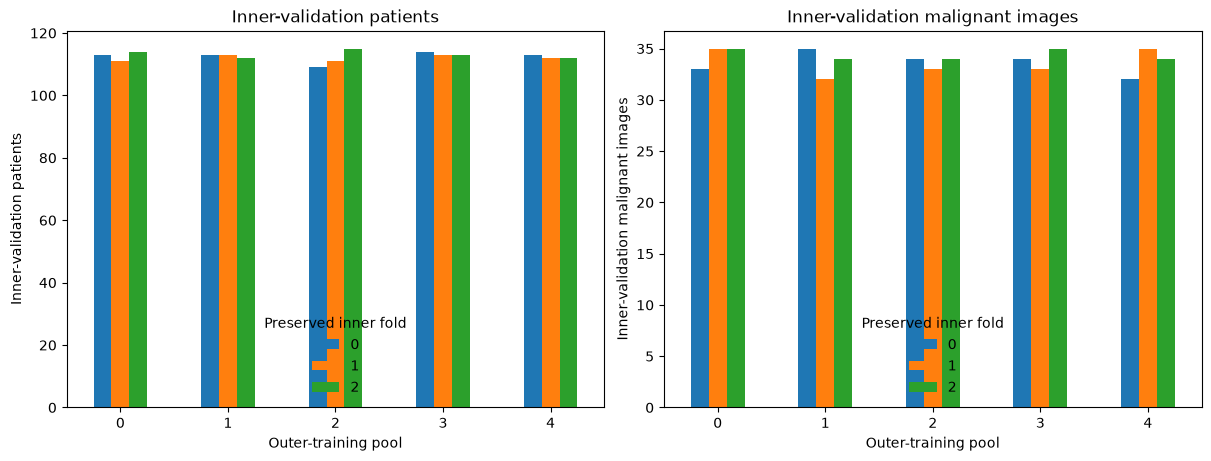

In [11]:
receipt = read_json(meta["suite"] / "memberships_receipt.json")
display(pd.DataFrame([{key: receipt[key] for key in ["status", "historical_membership_receipt_available", "original_row_order_used", "split_on_retained_rows", "seed_rule"]}]))
display(pd.DataFrame([receipt["versions"]]).T)
members = pd.read_csv(meta["suite"] / "inner_memberships_retained.csv")
assert members.groupby(["outer_fold", "patient_id"]).inner_fold.nunique().eq(1).all()
inner_audit = pd.read_csv(meta["suite"] / "inner_audit.csv")
assert inner_audit.patient_overlap.eq(0).all() and inner_audit.outer_patient_overlap.eq(0).all()
display(inner_audit)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, column, label in zip(axes, ["validation_patients", "validation_positive_images"], ["Inner-validation patients", "Inner-validation malignant images"]):
    table = inner_audit.pivot(index="outer_fold", columns="inner_fold", values=column)
    table.plot.bar(ax=ax, rot=0)
    ax.set(title=label, xlabel="Outer-training pool", ylabel=label)
    ax.legend(title="Preserved inner fold", frameon=False)
finish_figure(fig, "nested_inner_patient_and_case_support")

### Added diagnostic: 3. Inspect selected settings and every candidate

The complete 210-row table contains 42 recipes per outer pool, their three inner AP values, mean, spread and selected flag. These are training-only selection scores, not final OOF performance. The error bars below are standard deviation across three inner folds and are not confidence intervals.

,outer_fold,model,inner_best_average_precision,best_candidate_index,best_parameters
0,0,spline,0.053470,2,"{""classifier__C"": 0.1, ""preprocessor__smooth_a..."
1,0,random_forest,0.046931,1,"{""classifier__max_depth"": 4, ""classifier__max_..."
2,0,xgboost,0.045778,6,"{""classifier__learning_rate"": 0.05, ""classifie..."
3,1,spline,0.064980,2,"{""classifier__C"": 0.1, ""preprocessor__smooth_a..."
4,1,random_forest,0.062906,9,"{""classifier__max_depth"": null, ""classifier__m..."
5,1,xgboost,0.054674,2,"{""classifier__learning_rate"": 0.03, ""classifie..."
6,2,spline,0.077252,7,"{""classifier__C"": 1.0, ""preprocessor__smooth_a..."
7,2,random_forest,0.072754,2,"{""classifier__max_depth"": 4, ""classifier__max_..."
8,2,xgboost,0.075964,8,"{""classifier__learning_rate"": 0.1, ""classifier..."
9,3,spline,0.060540,3,"{""classifier__C"": 0.1, ""preprocessor__smooth_a..."


,outer_fold,model,candidate_index,parameters,mean_inner_average_precision,std_inner_average_precision,mean_fit_seconds,selected,inner_0_average_precision,inner_1_average_precision,inner_2_average_precision
18,0,random_forest,0,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04487,0.01293,0.68813,False,0.03905,0.06279,0.03276
19,0,random_forest,1,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04693,0.01555,0.68855,True,0.03845,0.06874,0.03360
20,0,random_forest,2,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04145,0.01288,0.64329,False,0.03554,0.05933,0.02950
21,0,random_forest,3,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04641,0.01438,0.64956,False,0.03827,0.06662,0.03435
22,0,random_forest,4,"{""classifier__max_depth"": 8, ""classifier__max_...",0.04089,0.01302,0.64560,False,0.03397,0.05913,0.02957
23,0,random_forest,5,"{""classifier__max_depth"": 8, ""classifier__max_...",0.04587,0.01343,0.71489,False,0.04012,0.06441,0.03307
24,0,random_forest,6,"{""classifier__max_depth"": 8, ""classifier__max_...",0.03509,0.01070,0.66111,False,0.03082,0.04980,0.02464
25,0,random_forest,7,"{""classifier__max_depth"": 8, ""classifier__max_...",0.03755,0.00661,0.64978,False,0.03955,0.04447,0.02864
26,0,random_forest,8,"{""classifier__max_depth"": null, ""classifier__m...",0.03673,0.01176,0.64771,False,0.03318,0.05258,0.02443
27,0,random_forest,9,"{""classifier__max_depth"": null, ""classifier__m...",0.04237,0.01088,0.64409,False,0.04019,0.05664,0.03026


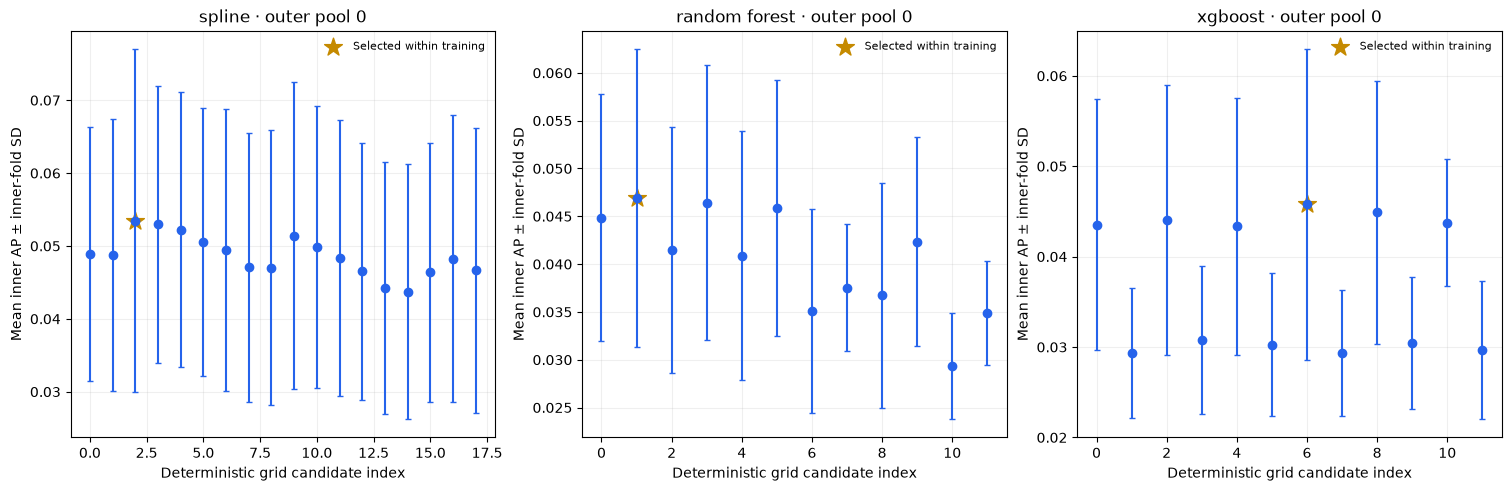

In [12]:
display(selected)
display(candidates.loc[candidates.outer_fold.eq(0)].sort_values(["model", "candidate_index"]).round(5))
assert len(candidates) == 210 and int(candidates.selected.sum()) == 15
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
for ax, model in zip(axes, ["spline", "random_forest", "xgboost"]):
    rows = candidates.loc[candidates.outer_fold.eq(0) & candidates.model.eq(model)]
    ax.errorbar(rows.candidate_index, rows.mean_inner_average_precision, yerr=rows.std_inner_average_precision, fmt="o", color="#2563eb", capsize=2)
    winner = rows.loc[rows.selected]
    ax.scatter(winner.candidate_index, winner.mean_inner_average_precision, marker="*", s=180, color="#C58A00", label="Selected within training")
    ax.set(title=model.replace("_", " ") + " · outer pool 0", xlabel="Deterministic grid candidate index", ylabel="Mean inner AP ± inner-fold SD")
    ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=8)
finish_figure(fig, "nested_all_candidate_scores_outer0")

### Added diagnostic: 4. Check how often each recipe was selected

Different training pools can choose different settings because malignant support is limited. Frequency describes selection stability; it does not identify a single recipe to refit on all development data or retrospectively change this experiment.

,model,best_parameters,outer_pools_selected
0,random_forest,"{""classifier__max_depth"": 4, ""classifier__max_...",3
1,random_forest,"{""classifier__max_depth"": 4, ""classifier__max_...",1
2,random_forest,"{""classifier__max_depth"": null, ""classifier__m...",1
3,spline,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",3
4,spline,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",1
5,spline,"{""classifier__C"": 1.0, ""preprocessor__smooth_a...",1
6,xgboost,"{""classifier__learning_rate"": 0.03, ""classifie...",1
7,xgboost,"{""classifier__learning_rate"": 0.03, ""classifie...",1
8,xgboost,"{""classifier__learning_rate"": 0.05, ""classifie...",1
9,xgboost,"{""classifier__learning_rate"": 0.05, ""classifie...",1


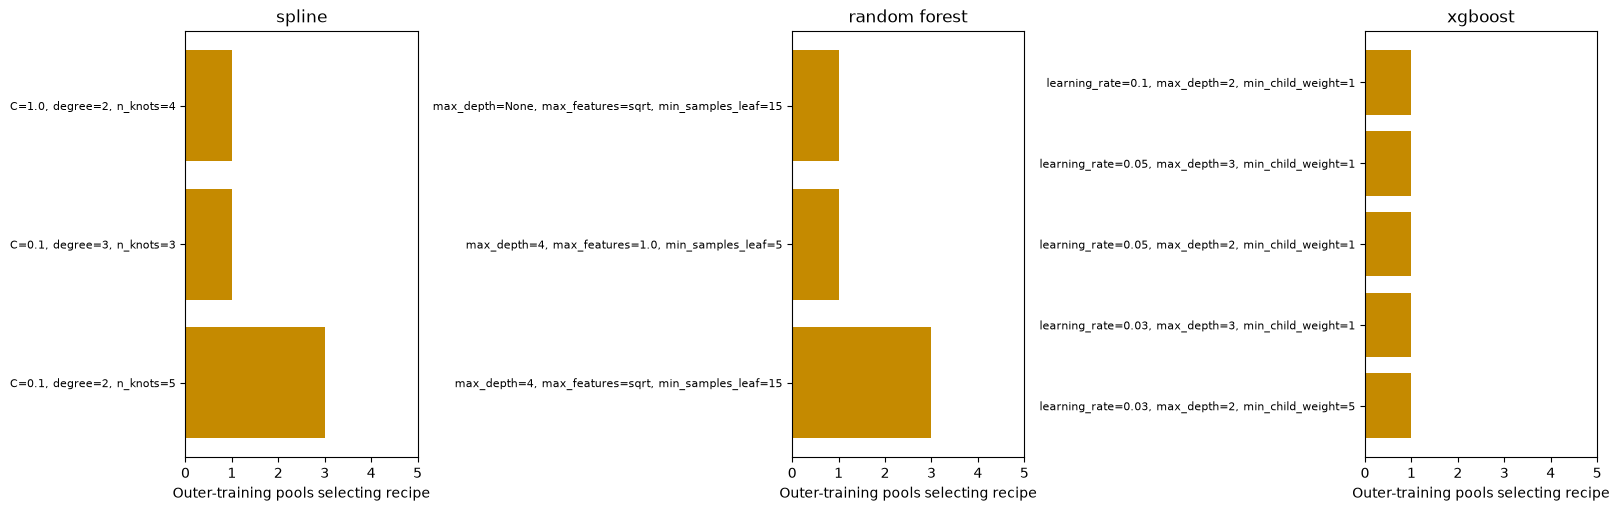

In [13]:
frequency = selected.groupby(["model", "best_parameters"]).size().reset_index(name="outer_pools_selected")
display(frequency)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
for ax, model in zip(axes, ["spline", "random_forest", "xgboost"]):
    rows = frequency.loc[frequency.model.eq(model)]
    labels = [", ".join(key.rsplit("__", 1)[-1] + "=" + str(value) for key, value in json.loads(parameters).items()) for parameters in rows.best_parameters]
    ax.barh(labels, rows.outer_pools_selected, color="#C58A00")
    ax.set(title=model.replace("_", " "), xlabel="Outer-training pools selecting recipe", xlim=(0, 5))
    ax.tick_params(axis="y", labelsize=8)
finish_figure(fig, "nested_recipe_selection_frequency")